In [11]:
import time
import random
import multiprocessing as mp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def simulate_room_detail(room_id):
    """
    Memodelkan konsumsi energi 24 jam untuk 1 ruangan.
    Menggabungkan jumlah orang (agen) dan 2 skenario penggunaan listrik.
    """
    random.seed(room_id)
    records = []

    for hour in range(24):
        # 1. Aturan Kehadiran Orang (Jam 08-18 ramai kelas, sisanya sepi)
        if 8 <= hour <= 18:
            occupants = random.randint(5, 35)
        else:
            occupants = random.randint(0, 3)

        # 2. Skenario 1: Tanpa Kebijakan (AC dingin 18-21°C, sering lupa matikan)
        if occupants > 0 or random.random() < 0.4:
            ac_temp_base = random.randint(18, 21)
            energy_base = (occupants * 0.15) + ((26 - ac_temp_base) * 0.85) + 1.2
        else:
            energy_base = 0.4

        # 3. Skenario 2: Dengan Kebijakan Hemat Energi (AC min 25°C, sensor otomatis)
        if occupants > 0:
            ac_temp_opt = 25
            energy_opt = (occupants * 0.12) + ((26 - ac_temp_opt) * 0.4) + 0.8
        else:
            energy_opt = 0.05

        records.append({
            "room_id": room_id,
            "hour": hour,
            "occupants": occupants,
            "baseline_kwh": round(energy_base, 2),
            "optimized_kwh": round(energy_opt, 2),
            "savings_kwh": round(energy_base - energy_opt, 2)
        })

    return records

print("Cell 1 selesai dieksekusi! Fungsi simulasi siap digunakan.")

Cell 1 selesai dieksekusi! Fungsi simulasi siap digunakan.


In [18]:
TOTAL_ROOMS = 200
NUM_CORES = mp.cpu_count()

print(f"Menjalankan simulasi {TOTAL_ROOMS} ruangan menggunakan {NUM_CORES} CPU Cores...")

start_time = time.time()

# Menjalankan komputasi paralel (mengirim pekerjaan ke seluruh CPU Core)
with mp.Pool(processes=NUM_CORES) as pool:
    results_nested = pool.map(simulate_room_detail, range(1, TOTAL_ROOMS + 1))

# Menggabungkan data hasil simulasi dari seluruh ruangan menjadi satu tabel (DataFrame)
all_records = [item for sublist in results_nested for item in sublist]
df = pd.DataFrame(all_records)

execution_time = time.time() - start_time

# Menghitung total konsumsi energi dan persentase penghematan
total_base = df["baseline_kwh"].sum()
total_opt = df["optimized_kwh"].sum()
pct_save = ((total_base - total_opt) / total_base) * 100

print(f"Simulasi selesai dalam {execution_time:.4f} detik!\n")
print(f"Total Energi Tanpa Kebijakan  : {total_base:,.2f} kWh")
print(f"Total Energi Dengan Kebijakan : {total_opt:,.2f} kWh")
print(f"Persentase Penghematan Energi : {pct_save:.2f}%")

Menjalankan simulasi 200 ruangan menggunakan 2 CPU Cores...
Simulasi selesai dalam 0.1234 detik!

Total Energi Tanpa Kebijakan  : 36,974.65 kWh
Total Energi Dengan Kebijakan : 10,780.62 kWh
Persentase Penghematan Energi : 70.84%


In [25]:
df.to_csv("hasil_simulasi_energi.csv", index=False)
print("File 'hasil_simulasi_energi.csv' berhasil disimpan!")

File 'hasil_simulasi_energi.csv' berhasil disimpan!


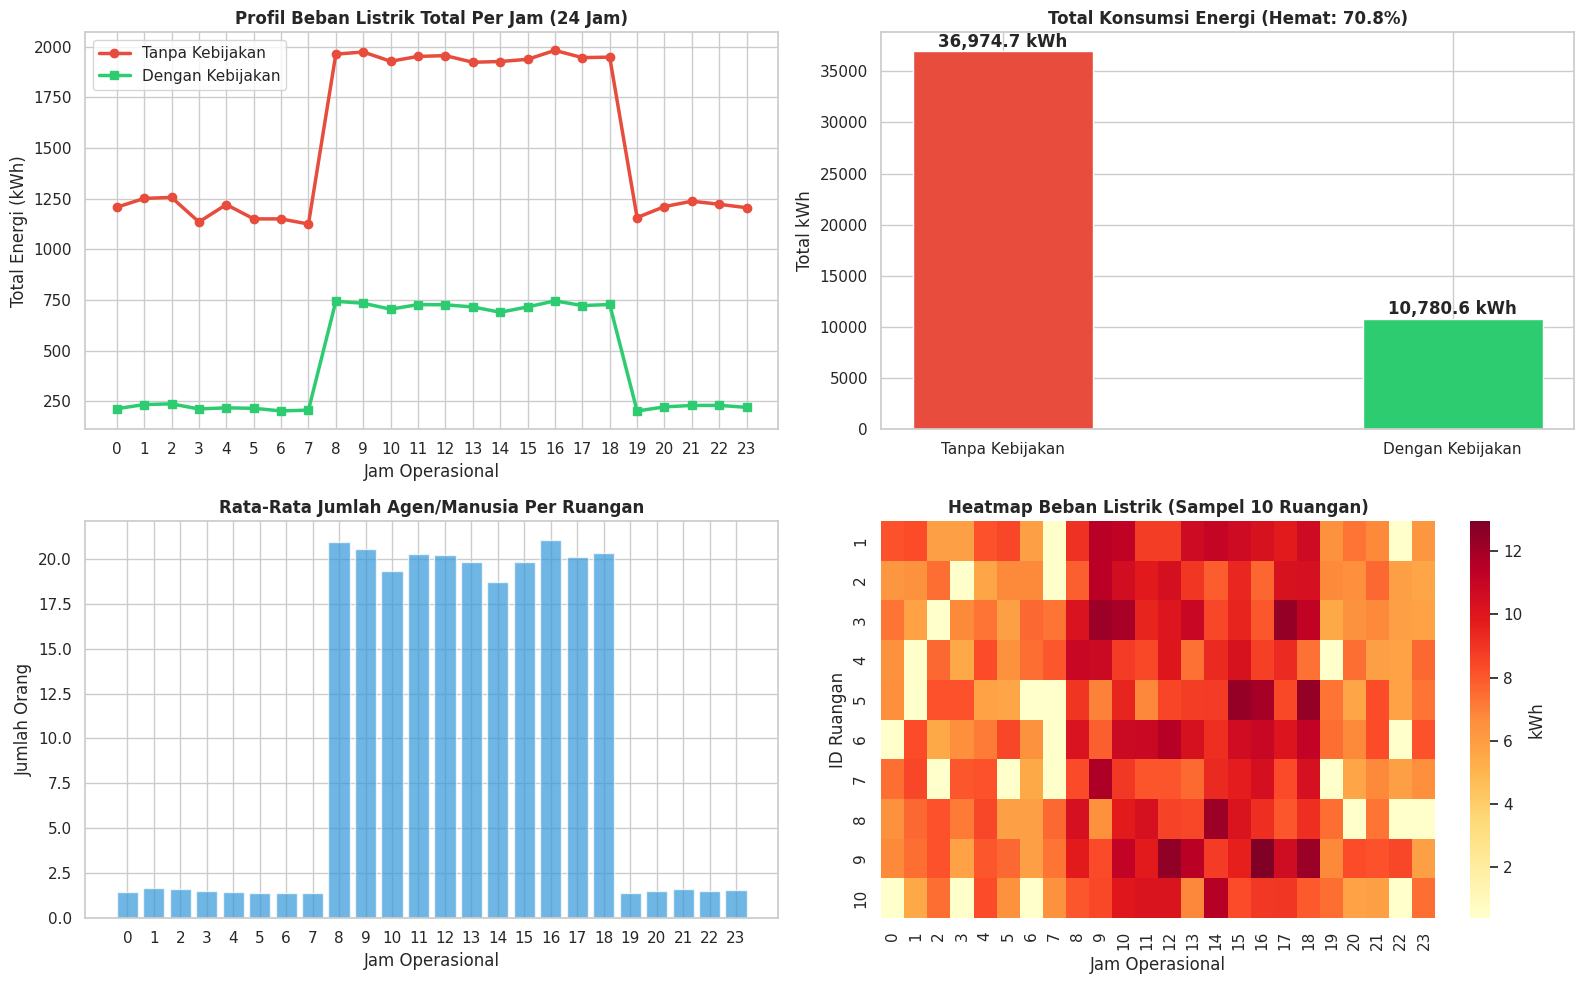

In [24]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Grafik 1: Tren Konsumsi Energi Per Jam (Time-Series)
hourly_summary = df.groupby("hour")[["baseline_kwh", "optimized_kwh"]].sum()
axes[0, 0].plot(hourly_summary.index, hourly_summary["baseline_kwh"], label="Tanpa Kebijakan", color="#e74c3c", linewidth=2.5, marker='o')
axes[0, 0].plot(hourly_summary.index, hourly_summary["optimized_kwh"], label="Dengan Kebijakan", color="#2ecc71", linewidth=2.5, marker='s')
axes[0, 0].set_title("Profil Beban Listrik Total Per Jam (24 Jam)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Jam Operasional")
axes[0, 0].set_ylabel("Total Energi (kWh)")
axes[0, 0].set_xticks(range(0, 24))
axes[0, 0].legend()

# Grafik 2: Total Penghematan Energi (Bar Chart)
bars = axes[0, 1].bar(["Tanpa Kebijakan", "Dengan Kebijakan"], [total_base, total_opt], color=["#e74c3c", "#2ecc71"], width=0.4)
axes[0, 1].set_title(f"Total Konsumsi Energi (Hemat: {pct_save:.1f}%)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Total kWh")
for bar in bars:
    yval = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2.0, yval + 50, f'{yval:,.1f} kWh', ha='center', va='bottom', fontweight='bold')

# Grafik 3: Rata-Rata Kehadiran Orang Per Jam
hourly_occ = df.groupby("hour")["occupants"].mean()
axes[1, 0].bar(hourly_occ.index, hourly_occ.values, color="#3498db", alpha=0.7)
axes[1, 0].set_title("Rata-Rata Jumlah Agen/Manusia Per Ruangan", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Jam Operasional")
axes[1, 0].set_ylabel("Jumlah Orang")
axes[1, 0].set_xticks(range(0, 24))

# Grafik 4: Heatmap Beban Listrik (Sampel 10 Ruangan)
pivot_df = df[df["room_id"] <= 10].pivot(index="room_id", columns="hour", values="baseline_kwh")
sns.heatmap(pivot_df, ax=axes[1, 1], cmap="YlOrRd", cbar_kws={'label': 'kWh'})
axes[1, 1].set_title("Heatmap Beban Listrik (Sampel 10 Ruangan)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Jam Operasional")
axes[1, 1].set_ylabel("ID Ruangan")

plt.tight_layout()
plt.show()